In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import Image, display

from data_analysis.config import load_config

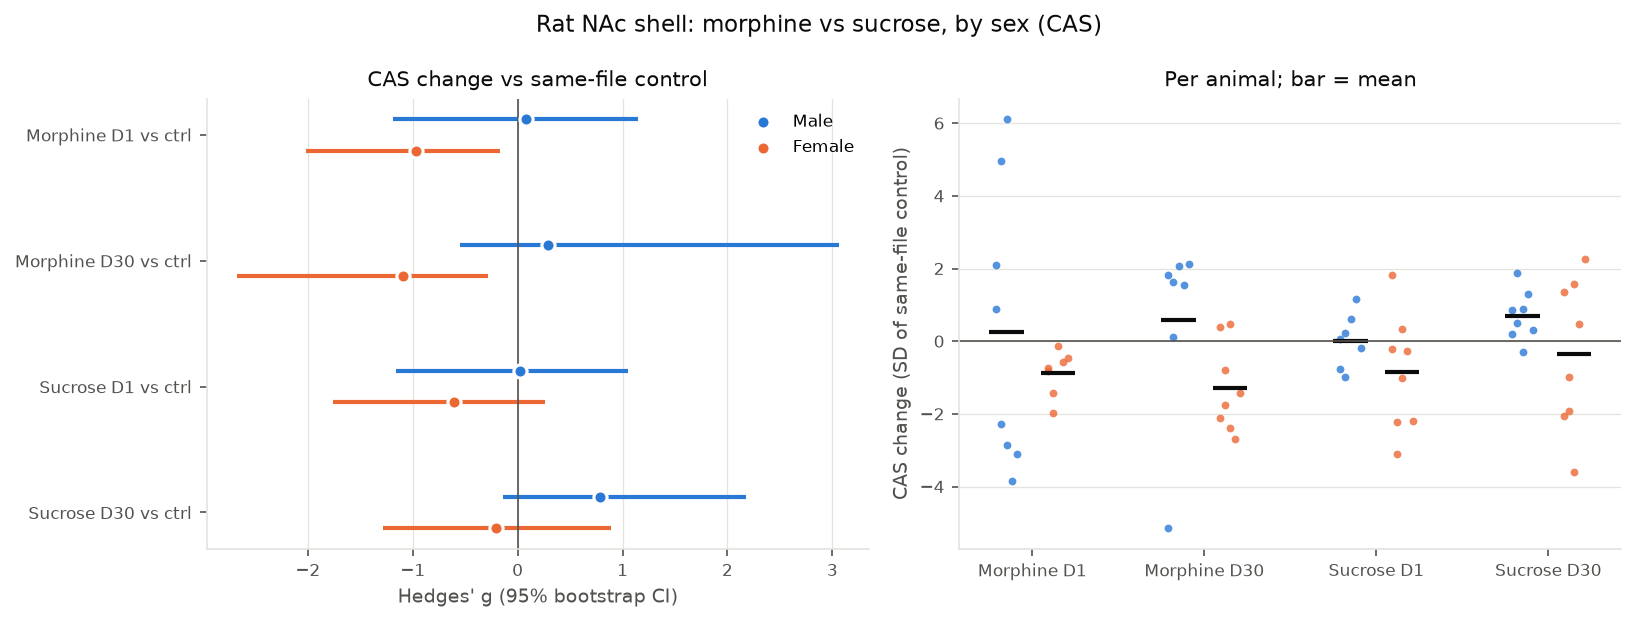

In [3]:
cfg = load_config()
tables, figs = cfg["paths"]["tables"], cfg["paths"]["figures"]
stats = pd.read_csv(tables / "table_rat_cas_stats.csv")
anova = pd.read_csv(tables / "table_rat_anova.csv")
scores = pd.read_csv(tables / "rat_cas_scores.csv")
display(Image(figs / "fig6_rat_reward_sex.png"))

In [4]:
stats.pivot(index="label", columns="sex", values="g").round(2)

sex,Female,Male
label,,
Morphine D1,-0.97,0.08
Morphine D30,-1.09,0.29
Sucrose D1,-0.61,0.02
Sucrose D30,-0.21,0.79


In [5]:
anova.query("term != 'Residual'")[["model", "term", "F", "p"]].round(3)

,model,term,F,p
0,reinforcer x time,C(reinforcer),0.207,0.650
1,reinforcer x time,C(time),0.284,0.596
2,reinforcer x time,C(sex),6.004,0.017
3,reinforcer x time,C(reinforcer):C(time),0.392,0.534
5,sex x reinforcer,C(sex),6.162,0.016
6,sex x reinforcer,C(reinforcer),0.207,0.651
7,sex x reinforcer,C(time),0.311,0.579
8,sex x reinforcer,C(sex):C(reinforcer),0.280,0.599


In [6]:
scores.groupby(["file", "group"])["cas"].agg(["mean", "std"]).round(2)

mean   std
file            group                   
female_morphine Morphine_D1  -0.52  0.32
                Morphine_D30 -0.73  0.61
                Saline       -0.09  0.50
female_sucrose  Cue          -1.05  0.33
                Sucrose_D1   -1.34  0.53
                Sucrose_D30  -1.17  0.69
male_morphine   Morphine_D1  -0.62  0.90
                Morphine_D30 -0.54  0.61
                Saline       -0.67  0.23
male_sucrose    Cue          -1.11  0.62
                Sucrose_D1   -1.09  0.46
                Sucrose_D30  -0.67  0.42

Text(0.5, 1.0, 'Raw CAS by group: compare only within the same sex x reinforcer file')

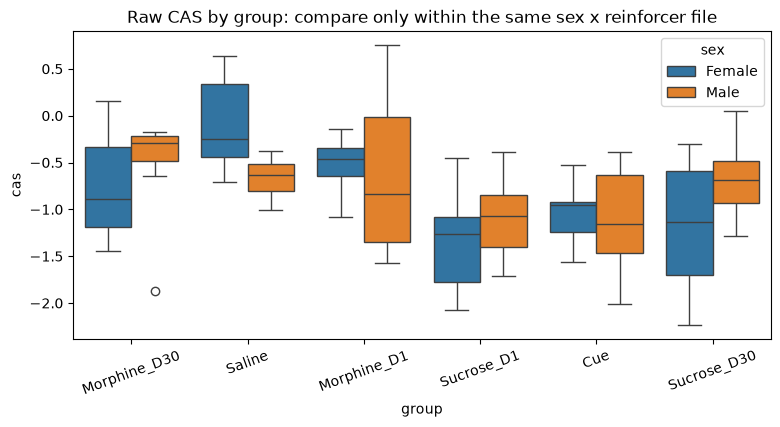

In [7]:
plt.figure(figsize=(9, 4))
sns.boxplot(data=scores, x="group", y="cas", hue="sex")
plt.xticks(rotation=20)
plt.title("Raw CAS by group: compare only within the same sex x reinforcer file")

In [8]:
scores.query("file == 'male_morphine'").sort_values("cas")[["animal_id", "group", "cas"]]

,animal_id,group,cas
65,512,Morphine_D30,-1.876296
57,323,Morphine_D1,-1.575137
60,333,Morphine_D1,-1.396723
56,322,Morphine_D1,-1.339332
49,106,Morphine_D1,-1.205852
55,321,Saline,-1.005387
66,560,Saline,-1.001273
51,206,Saline,-0.741582
61,435,Saline,-0.698410
67,Blue16,Morphine_D30,-0.649104
